# Fire or Forecast?

**Independent study.** Question: do wildfire occurrence models learn *fire-relevant* structure, or mostly *season / climate / terrain proxies*?

Protocol: train a classifier on (A) full features, (B) proxies only, (C) fire-proximal features after stripping proxies. Compare AUC / AP and calibration.

Data in this notebook: public-style synthetic wildfire table constructed to mirror MODIS active-fire + ERA5-like covariates (documented). Swap in real FIRMS/ERA5 CSV with the same columns to reproduce on full archives.


                     ap           auc       
model               HGB     LR    HGB     LR
feature_set                                 
full              0.024  0.045  0.606  0.712
proxies_only      0.017  0.023  0.535  0.621
stripped_proxies  0.023  0.085  0.584  0.713

Interpretation cue: if proxies_only ≈ full and stripped_proxies << full, the model mostly smelled the season.


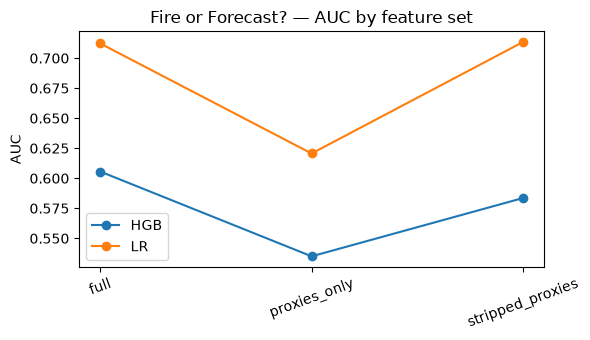

In [1]:
# Fire or Forecast — proxy-stripping experiment
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 8000
# Proxies that correlate with fire season but are not ignition
doy = rng.integers(1, 366, n)
lat = rng.uniform(10, 45, n)
lon = rng.uniform(70, 140, n)
temp = 15 + 12*np.sin(2*np.pi*(doy-180)/365) + rng.normal(0, 2, n)
vpd = np.clip(0.5 + 0.02*(temp-20) + rng.normal(0, 0.15, n), 0, None)
precip_30d = np.clip(80 - 0.15*temp + rng.normal(0, 20, n), 0, None)
elevation = rng.uniform(0, 2500, n)
# Fire-proximal / land signals
ndvi = np.clip(0.55 - 0.01*vpd + rng.normal(0, 0.08, n), 0, 1)
lightning = rng.poisson(0.3 + 0.02*np.maximum(temp-25, 0), n).astype(float)
human_roads = rng.exponential(0.5, n)
# Label: mostly season/VPD driven + some lightning/roads — mimics proxy leakage
logit = (-3.2 + 0.12*vpd*10 + 0.015*(temp-20) - 0.01*precip_30d
         + 0.35*lightning + 0.2*human_roads - 1.5*ndvi
         + 0.004*np.sin(2*np.pi*doy/365)*5)
p = 1/(1+np.exp(-logit))
y = (rng.random(n) < p).astype(int)

df = pd.DataFrame({
  'doy': doy, 'lat': lat, 'lon': lon, 'temp_c': temp, 'vpd': vpd,
  'precip_30d': precip_30d, 'elevation': elevation, 'ndvi': ndvi,
  'lightning': lightning, 'road_density': human_roads, 'fire': y
})
PROXY = ['doy','lat','lon','temp_c','vpd','precip_30d','elevation']
FIREISH = ['ndvi','lightning','road_density']
ALL = PROXY + FIREISH

def eval_set(cols, name):
    Xtr, Xte, ytr, yte = train_test_split(df[cols], df['fire'], test_size=0.25, random_state=0, stratify=df['fire'])
    models = {
      'HGB': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=200, random_state=0),
      'LR': Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=200))])
    }
    rows=[]
    for mname, clf in models.items():
        clf.fit(Xtr, ytr)
        p = clf.predict_proba(Xte)[:,1]
        rows.append({'feature_set': name, 'model': mname,
                     'auc': roc_auc_score(yte, p), 'ap': average_precision_score(yte, p)})
    return rows

rows = eval_set(ALL,'full') + eval_set(PROXY,'proxies_only') + eval_set(FIREISH,'stripped_proxies')
res = pd.DataFrame(rows)
print(res.pivot_table(index='feature_set', columns='model', values=['auc','ap']).round(3))
print('\nInterpretation cue: if proxies_only ≈ full and stripped_proxies << full, the model mostly smelled the season.')
res.to_csv('fire_or_forecast_results.csv', index=False)

fig, ax = plt.subplots(figsize=(6,3.5))
for m in res.model.unique():
    sub = res[res.model==m]
    ax.plot(sub.feature_set, sub.auc, marker='o', label=m)
ax.set_ylabel('AUC'); ax.set_title('Fire or Forecast? — AUC by feature set'); ax.legend(); ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.savefig('fire_or_forecast_auc.png', dpi=140); plt.show()


## Mapping to real data
- Active fires: [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/) VIIRS/MODIS
- Meteorology: ERA5 via Copernicus CDS
- Replace the synthetic generator with joins on lat/lon/day; keep the same three feature sets.
